# Tutorial: Using the Analytical Module in Soft Potato

The `softpotato.analytical` module provides a comprehensive collection of exact mathematical solutions, empirical relations, and diagnostic equations standard across electrochemistry.

---

## 1. What is the Analytical Module?

> **Important:** **No Simulations are Run Here!**
>
> Unlike `softpotato.solver`—which numerically discretizes space and steps through time to solve partial differential equations (PDEs)—the `analytical` module **does not simulate anything**. Instead, it consists of **pure, hard-coded algebraic equations** derived analytically from electrochemical theory. When you call an equation, it evaluates the exact mathematical expression instantly.

### Submodule Organization

Equations are grouped into domain-specific submodules based on experimental technique and physical phenomenon:

| Submodule | Focus | Example Equations |
| :--- | :--- | :--- |
| `softpotato.analytical.step` | Potential & current steps | `cottrell()`, `cottrell_spherical()`, `anson()`, `sand()` |
| `softpotato.analytical.hydrodynamics` | Forced convection & RDE / RRDE | `levich()`, `koutecky_levich()`, `collection_efficiency()` |
| `softpotato.analytical.kinetics` | Thermodynamics & charge-transfer | `butler_volmer()`, `nernst()`, `tafel()` |
| `softpotato.analytical.secm` | Scanning Electrochemical Microscopy | `secm_approach_curve()`, `secm_tip_current()` |
| `softpotato.analytical.voltammetry` | Voltammetric diagnostics | `randles_sevcik()`, `nicholson_psi()` |
| `softpotato.analytical.microelectrodes` | Ultramicroelectrodes (UMEs) | `microdisc_limiting_current()`, `mahon_oldham_transient()` |

### How to Import and Call Equations

You can import equations in three equivalent ways:

```python
# Option 1: Directly from the specific submodule (recommended for clarity)
from softpotato.analytical.step import cottrell

# Option 2: From the analytical subpackage
from softpotato.analytical import cottrell

# Option 3: From the top-level package
import softpotato as sp
# sp.cottrell(...)
```

All equations accept either single numbers (e.g. `float`) or array-like objects (e.g. `numpy.ndarray`, `list`) and evaluate in a fully vectorized manner. The following sections show some examples on how to use the analytical module to call typical electrochemical equations.

---

## 2. Potential Steps: `cottrell()`

The Cottrell equation calculates the diffusion-controlled Faradaic current transient $I(t)$ following an instantaneous potential step to a planar electrode into the mass-transport-limited regime:

$$I(t) = \frac{n F A \sqrt{D} c^*}{\sqrt{\pi t}}$$

The function `cottrell(t, n=1, D=1e-5, c_bulk=1e-3, area=1.0)` computes this transient.

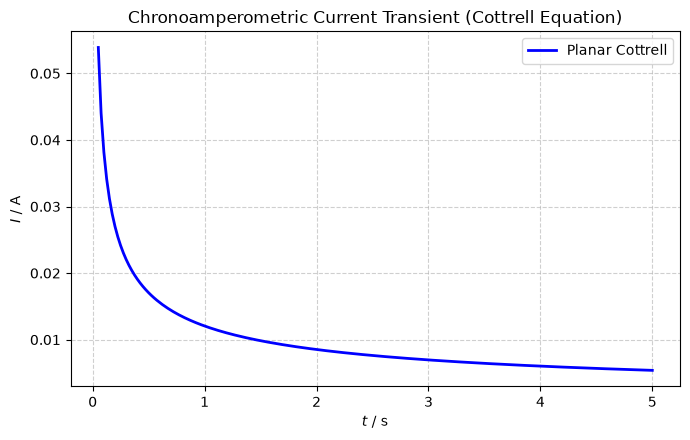

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.step import cottrell

# Time array from 0.05 s to 5.0 s (avoid t = 0 to prevent division by zero)
t = np.linspace(0.05, 5.0, 200)

# Calculate current transient for a 1-electron reduction
# Parameters: n = 1, D = 1e-5 cm^2/s, c_bulk = 1e-3 mol/cm^3 (1 mM), area = 0.07 cm^2
i_transient = cottrell(t=t, n=1, D=1e-5, c_bulk=1e-3, area=0.07)

# Plot current transient
plt.figure(figsize=(7, 4.5))
plt.plot(t, i_transient, "b-", lw=2, label="Planar Cottrell")
plt.xlabel("$t$ / s")
plt.ylabel(r"$I$ / A")
plt.title("Chronoamperometric Current Transient (Cottrell Equation)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---

## 3. Hydrodynamics: `levich()`

The Levich equation calculates the steady-state diffusion-limited current $I_L$ at a Rotating Disk Electrode (RDE) under laminar convective-diffusion flow:

$$I_L = 0.620 \, n F A D^{2/3} \omega^{1/2} \nu^{-1/6} c^*$$

In `softpotato.analytical.hydrodynamics.levich`, you can supply rotation rate either in angular velocity `omega` ($\text{rad}\cdot\text{s}^{-1}$) or directly in `rpm`.

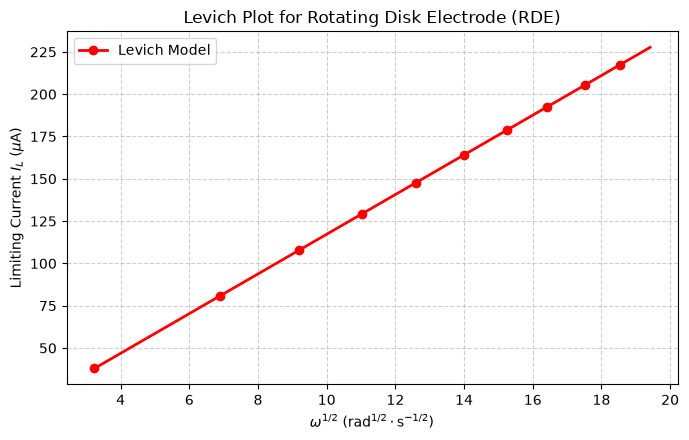

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.hydrodynamics import levich

# Rotation speeds in RPM
rpm_values = np.linspace(100, 3600, 100)

# Calculate limiting current (A)
# Area = 0.196 cm^2 (5 mm OD disk), D = 1e-5 cm^2/s, c_bulk = 1e-6 mol/cm^3 (1 mM), nu = 0.01 cm^2/s
i_lim = levich(rpm=rpm_values, n=1, D=1e-5, c_bulk=1e-6, area=0.196, nu=0.01)

# Plot Levich curve (I vs sqrt(omega))
omega_rad_s = (2.0 * np.pi / 60.0) * rpm_values
sqrt_omega = np.sqrt(omega_rad_s)

plt.figure(figsize=(7, 4.5))
plt.plot(sqrt_omega, i_lim * 1e6, "r-o", markevery=10, lw=2, label="Levich Model")
plt.xlabel(r"$\omega^{1/2}$ ($\text{rad}^{1/2}\cdot\text{s}^{-1/2}$)")
plt.ylabel(r"Limiting Current $I_L$ ($\mu\text{A}$)")
plt.title("Levich Plot for Rotating Disk Electrode (RDE)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---

## 4. Electrode Kinetics: `butler_volmer()`

The Butler–Volmer equation models current density or total current as a function of the activation overpotential $\eta = E - E_{\text{eq}}$:

$$I(\eta) = I_0 \left[ \exp\left( \frac{(1 - \alpha) n F \eta}{R T} \right) - \exp\left( -\frac{\alpha n F \eta}{R T} \right) \right]$$

The function `butler_volmer(eta, i0=1.0, alpha=0.5, n=1)` calculates this response under pure activation control.

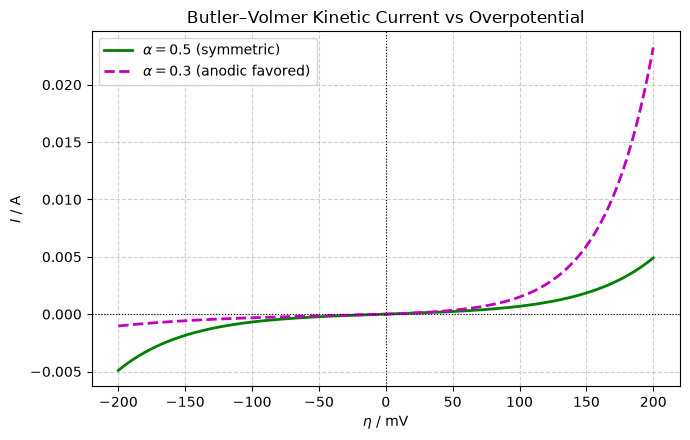

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.kinetics import butler_volmer

# Overpotential range: -0.2 V (cathodic) to +0.2 V (anodic)
eta = np.linspace(-0.2, 0.2, 200)

# Calculate current for symmetric (alpha = 0.5) and asymmetric transfer coefficients
i_sym = butler_volmer(eta, i0=1e-4, alpha=0.5, n=1)
i_asym = butler_volmer(eta, i0=1e-4, alpha=0.3, n=1)

# Plot Butler-Volmer curves
plt.figure(figsize=(7, 4.5))
plt.plot(eta * 1e3, i_sym, "g-", lw=2, label=r"$\alpha = 0.5$ (symmetric)")
plt.plot(eta * 1e3, i_asym, "m--", lw=2, label=r"$\alpha = 0.3$ (anodic favored)")
plt.axhline(0, color="k", lw=0.8, ls=":")
plt.axvline(0, color="k", lw=0.8, ls=":")
plt.xlabel(r"$\eta$ / mV")
plt.ylabel(r"$I$ / A")
plt.title("Butler–Volmer Kinetic Current vs Overpotential")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---

## 5. SECM Approach Curves: `secm_approach_curve()`

Scanning Electrochemical Microscopy (SECM) approach curves describe how the normalized steady-state tip current $I_T = i_T / i_{T,\infty}$ changes as an ultramicroelectrode (UME) tip approaches a substrate:

- **Insulating substrate** ($\kappa = 0$, pure negative feedback): hindered diffusion blocks mediator access to the tip, causing $I_T \to 0$ as $L \to 0$.
- **Conductive substrate** ($\kappa \to \infty$, pure positive feedback): mediator regeneration at the substrate enhances tip flux, causing $I_T > 1$ as $L \to 0$.
- **Finite substrate kinetics** ($0 < \kappa < \infty$): smoothly interpolates between positive and negative feedback curves.

The parameter $L = d / a$ is the tip-substrate distance $d$ normalized by the tip radius $a$, and $RG = r_g / a$ is the insulator sheath ratio.

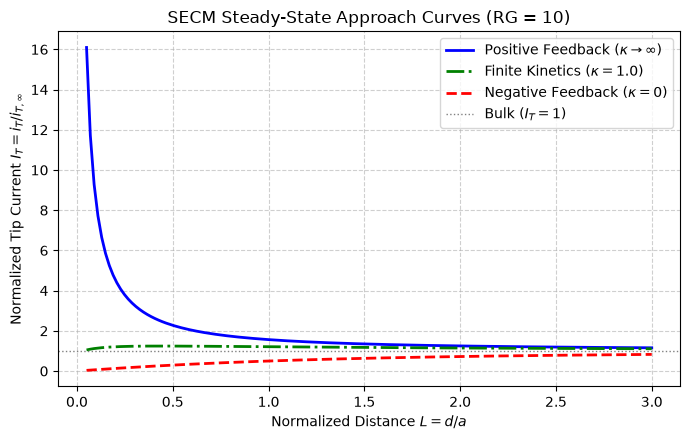

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.secm import secm_approach_curve

# Normalized distance L = d / a
L = np.linspace(0.05, 3.0, 150)
RG = 10.0  # Standard tip sheath ratio

# Compute normalized currents across three kinetic regimes
i_pos = secm_approach_curve(L=L, RG=RG, kappa=np.inf)  # Conducting substrate
i_kin = secm_approach_curve(L=L, RG=RG, kappa=1.0)     # Finite kinetics (kappa = 1)
i_neg = secm_approach_curve(L=L, RG=RG, kappa=0.0)     # Insulating substrate

# Plot SECM approach curves
plt.figure(figsize=(7, 4.5))
plt.plot(L, i_pos, "b-", lw=2, label=r"Positive Feedback ($\kappa \to \infty$)")
plt.plot(L, i_kin, "g-.", lw=2, label=r"Finite Kinetics ($\kappa = 1.0$)")
plt.plot(L, i_neg, "r--", lw=2, label=r"Negative Feedback ($\kappa = 0$)")
plt.axhline(1.0, color="gray", lw=1, ls=":", label="Bulk ($I_T = 1$)")
plt.xlabel("Normalized Distance $L = d / a$")
plt.ylabel(r"Normalized Tip Current $I_T = i_T / i_{T,\infty}$")
plt.title("SECM Steady-State Approach Curves (RG = 10)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---

## 6. Summary: Calling Any Analytical Equation

Whenever you want to use an equation from `softpotato.analytical`:

1. **Locate the submodule**: Pick `step`, `hydrodynamics`, `kinetics`, `secm`, `voltammetry`, or `microelectrodes`.
2. **Pass your independent variable**: Supply either a single number or a 1D NumPy array (e.g. `t`, `rpm`, `eta`, or `L`).
3. **Set physical parameters**: Pass relevant values ($n$, $D$, $c_{\text{bulk}}$, $A$, etc.) using consistent units (SI or CGS).
4. **Collect the evaluated result**: You instantly get back a float or NumPy array ready for plotting, data fitting, or benchmarking numerical simulations.

To see the list of equations available and their parameters, visit [softpotato.analytical](/api/analytical/).